J-1. Verifikasilingkungankerja
Tujuan: mengetahui persis mesin apa yang dipakai. Semua kesimpulan performa nanti hanya berlaku
untuk spesifikasi ini.

In [1]:
import sys, platform, multiprocessing

print("Python  :", sys.version.split()[0])
print("OS      :", platform.platform())
print("CPU core:", multiprocessing.cpu_count())

for nama in ["pandas", "numpy", "pyarrow", "matplotlib", "psutil"]:
    try:
        mod = __import__(nama)
        print(f"{nama:11s}: {mod.__version__}")
    except ImportError:
        print(f"{nama:11s}: BELUM TERPASANG")

Python  : 3.13.16
OS      : Linux-6.6.122+-x86_64-with-glibc2.39
CPU core: 2
pandas     : 2.2.3
numpy      : 2.1.3
pyarrow    : 23.0.1
matplotlib : 3.10.0
psutil     : 5.9.5


J-2. MenghubungkanGoogle Drivedanmenyiapkanstruktur folder

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os
DIR_KERJA  = "/content/data"
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum1"
os.makedirs(DIR_KERJA, exist_ok=True)
os.makedirs(DIR_SIMPAN, exist_ok=True)
print(os.listdir(DIR_SIMPAN))

Mounted at /content/drive
[]


J-3. Menyiapkanalat ukurwaktudanmemori

In [3]:
import time, os, gc, psutil

proses  = psutil.Process(os.getpid())
catatan = []

def rss_mb():
    return proses.memory_info().rss / 1024**2

def ukur(label, fungsi):
    """Menjalankan fungsi tanpa argumen, mencatat durasi dan pertumbuhan memori."""
    m0, t0 = rss_mb(), time.perf_counter()
    hasil  = fungsi()
    detik  = time.perf_counter() - t0
    delta  = rss_mb() - m0
    catatan.append({"langkah": label, "detik": round(detik, 2),
                    "delta_rss_mb": round(delta, 1)})
    print(f"[{label}] {detik:.2f} s | RSS {delta:+.1f} MB")
    return hasil

J-4. Mengunduh dataset daninspeksi awal

In [4]:
import urllib.request, shutil

URL  = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet"
PATH = os.path.join(DIR_KERJA, "yellow_tripdata_2023-01.parquet")
SINTETIS = False

def unduh(url, path):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=180) as r, open(path, "wb") as f:
        shutil.copyfileobj(r, f)

if not os.path.exists(PATH):
    try:
        ukur("unduh dataset", lambda: unduh(URL, PATH))
    except Exception as e:
        print("Unduhan gagal:", e)
        if os.path.exists(PATH):
            os.remove(PATH)

[unduh dataset] 0.35 s | RSS +1.9 MB


J-4b · Cadangan otomatis (hanya aktif kalau unduhan gagal)

In [5]:
import numpy as np, pandas as pd
import pyarrow.parquet as pq

def bangkitkan_sintetis(n=5_000_000, seed=42):
    rng    = np.random.default_rng(seed)
    awal   = pd.Timestamp("2023-01-01")
    pickup = awal + pd.to_timedelta(rng.integers(0, 31*24*60, n), unit="min")
    durasi = rng.integers(1, 90, n)
    return pd.DataFrame({
        "tpep_pickup_datetime":  pickup,
        "tpep_dropoff_datetime": pickup + pd.to_timedelta(durasi, unit="min"),
        "passenger_count":       rng.integers(1, 5, n).astype("float64"),
        "trip_distance":         np.round(rng.gamma(2.0, 1.6, n), 2),
        "payment_type":          rng.integers(1, 5, n).astype("int64"),
        "fare_amount":           np.round(rng.gamma(4.0, 3.0, n), 2),
        "tip_amount":            np.round(rng.gamma(1.5, 1.2, n), 2),
    }).assign(total_amount=lambda d: (d.fare_amount + d.tip_amount + 3.0).round(2))

def parquet_valid(path):
    try:
        pq.ParquetFile(path)
        return True
    except Exception:
        return False

if not (os.path.exists(PATH) and parquet_valid(PATH)):
    SINTETIS = True
    # timestamp dipaksa ke mikrodetik agar bisa dibaca Spark 3.5
    bangkitkan_sintetis().to_parquet(PATH, index=False,
                                     coerce_timestamps="us", allow_truncated_timestamps=True)
    gc.collect()
    print("Dataset SINTETIS dibuat di", PATH, "(bukan data nyata NYC TLC)")
else:
    print("Memakai data asli NYC TLC.")

Memakai data asli NYC TLC.


J-4 (lanjutan) · Inspeksi metadata

In [6]:
print("Ukuran file:", round(os.path.getsize(PATH) / 1024**2, 1), "MB")

meta = pq.ParquetFile(PATH).metadata
print("Jumlah baris :", f"{meta.num_rows:,}")
print("Jumlah kolom :", meta.num_columns)
print("Row group    :", meta.num_row_groups)
print("Nama kolom   :", pq.ParquetFile(PATH).schema.names)

Ukuran file: 45.5 MB
Jumlah baris : 3,066,766
Jumlah kolom : 19
Row group    : 1
Nama kolom   : ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']


J-5 · Muat data & ukur memori

In [7]:
KOLOM = ["tpep_pickup_datetime", "tpep_dropoff_datetime",
         "passenger_count", "trip_distance", "payment_type",
         "fare_amount", "tip_amount", "total_amount"]

penuh = ukur("baca semua kolom", lambda: pd.read_parquet(PATH))
mem_penuh = penuh.memory_usage(deep=True).sum() / 1024**2
print("Dimensi:", penuh.shape)
print("Memori :", round(mem_penuh, 1), "MB")

del penuh
gc.collect()

df = ukur("baca kolom terpilih", lambda: pd.read_parquet(PATH, columns=KOLOM))
mem_pilih = df.memory_usage(deep=True).sum() / 1024**2
print("Dimensi:", df.shape)
print("Memori :", round(mem_pilih, 1), "MB")
df.head()

[baca semua kolom] 1.80 s | RSS +482.3 MB
Dimensi: (3066766, 19)
Memori : 565.6 MB
[baca kolom terpilih] 1.18 s | RSS +221.5 MB
Dimensi: (3066766, 8)
Memori : 187.2 MB


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount
0,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,2,9.3,0.00,14.30
1,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1,7.9,4.00,16.90
2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1,14.9,15.00,34.90
3,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1,12.1,0.00,20.85
4,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1,11.4,3.28,19.68


In [8]:
df.info(memory_usage="deep")
df.memory_usage(deep=True).sort_values(ascending=False) / 1024**2

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3066766 entries, 0 to 3066765
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   passenger_count        float64       
 3   trip_distance          float64       
 4   payment_type           int64         
 5   fare_amount            float64       
 6   tip_amount             float64       
 7   total_amount           float64       
dtypes: datetime64[us](2), float64(5), int64(1)
memory usage: 187.2 MB


,0
tpep_pickup_datetime,23.397568
payment_type,23.397568
tpep_dropoff_datetime,23.397568
passenger_count,23.397568
trip_distance,23.397568
tip_amount,23.397568
fare_amount,23.397568
total_amount,23.397568
Index,0.000126


In [9]:
sebelum = df.memory_usage(deep=True).sum() / 1024**2

df["passenger_count"] = pd.to_numeric(df["passenger_count"], downcast="float")
df["payment_type"]    = df["payment_type"].fillna(0).astype("int8").astype("category")
for kol in ["trip_distance", "fare_amount", "tip_amount", "total_amount"]:
    df[kol] = pd.to_numeric(df[kol], downcast="float")

sesudah = df.memory_usage(deep=True).sum() / 1024**2
print(f"{sebelum:.1f} MB -> {sesudah:.1f} MB  (hemat {100*(1-sesudah/sebelum):.1f}%)")
print((df.memory_usage(deep=True) / 1024**2).round(2))
df.dtypes

187.2 MB -> 119.9 MB  (hemat 35.9%)
Index                     0.00
tpep_pickup_datetime     23.40
tpep_dropoff_datetime    23.40
passenger_count          11.70
trip_distance            23.40
payment_type              2.92
fare_amount              11.70
tip_amount               11.70
total_amount             11.70
dtype: float64


,0
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float32
trip_distance,float64
payment_type,category
fare_amount,float32
tip_amount,float32
total_amount,float32


In [10]:
# Pengukuran tambahan (pandas >= 2.0): dtype_backend pyarrow
df_pa  = ukur("baca kolom terpilih (pyarrow backend)",
              lambda: pd.read_parquet(PATH, columns=KOLOM, dtype_backend="pyarrow"))
mem_pa = df_pa.memory_usage(deep=True).sum() / 1024**2
print("Memori pyarrow backend:", round(mem_pa, 1), "MB")
del df_pa
gc.collect()

[baca kolom terpilih (pyarrow backend)] 0.78 s | RSS +188.7 MB
Memori pyarrow backend: 190.1 MB


0

J-6 · Kualitas data (veracity)

In [11]:
df["durasi_menit"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60

print(df[["trip_distance", "durasi_menit", "total_amount"]].describe())
print("\nNilai kosong per kolom:\n", df.isna().sum())

anomali = {
    "jarak <= 0"         : (df["trip_distance"] <= 0).sum(),
    "durasi <= 0"        : (df["durasi_menit"]  <= 0).sum(),
    "durasi > 180 menit" : (df["durasi_menit"]  > 180).sum(),
    "total_amount <= 0"  : (df["total_amount"]  <= 0).sum(),
}
for k, v in anomali.items():
    print(f"{k:22s}: {v:,} baris ({100*v/len(df):.2f}%)")

       trip_distance  durasi_menit  total_amount
count   3.066766e+06  3.066766e+06  3.066766e+06
mean    3.847342e+00  1.566900e+01  2.702038e+01
std     2.495838e+02  4.259435e+01  2.212666e+01
min     0.000000e+00 -2.920000e+01 -7.510000e+02
25%     1.060000e+00  7.116667e+00  1.540000e+01
50%     1.800000e+00  1.151667e+01  2.016000e+01
75%     3.330000e+00  1.830000e+01  2.870000e+01
max     2.589281e+05  1.002918e+04  1.169400e+03

Nilai kosong per kolom:
 tpep_pickup_datetime         0
tpep_dropoff_datetime        0
passenger_count          71743
trip_distance                0
payment_type                 0
fare_amount                  0
tip_amount                   0
total_amount                 0
durasi_menit                 0
dtype: int64
jarak <= 0            : 45,862 baris (1.50%)
durasi <= 0           : 1,121 baris (0.04%)
durasi > 180 menit    : 3,048 baris (0.10%)
total_amount <= 0     : 25,772 baris (0.84%)


In [12]:
layak = (
    (df["trip_distance"] > 0) & (df["trip_distance"] < 100) &
    df["durasi_menit"].between(1, 180) &
    (df["total_amount"] > 0)
)
bersih = df.loc[layak].copy()
print(f"{len(df):,} baris -> {len(bersih):,} baris  (dibuang {len(df)-len(bersih):,})")

3,066,766 baris -> 2,986,911 baris  (dibuang 79,855)


J-7 · Chunking

In [16]:
CSV = os.path.join(DIR_KERJA, "trips.csv")
ukur("tulis CSV", lambda: bersih.to_csv(CSV, index=False))

ukuran_parquet = os.path.getsize(PATH) / 1024**2
ukuran_csv     = os.path.getsize(CSV)  / 1024**2
print("Parquet:", round(ukuran_parquet, 1), "MB")
print("CSV    :", round(ukuran_csv, 1), "MB")

[tulis CSV] 42.95 s | RSS +5.7 MB
Parquet: 45.5 MB
CSV    : 226.2 MB


In [17]:
def agregasi_bertahap(path, ukuran_chunk=500_000):
    jumlah_baris = 0
    total_nilai  = 0.0
    per_jam      = {}
    potongan = pd.read_csv(
        path,
        usecols=["tpep_pickup_datetime", "total_amount"],
        parse_dates=["tpep_pickup_datetime"],
        chunksize=ukuran_chunk)
    for chunk in potongan:
        jumlah_baris += len(chunk)
        total_nilai  += chunk["total_amount"].sum()
        for jam, sub in chunk.groupby(chunk["tpep_pickup_datetime"].dt.hour):
            n, nilai = per_jam.get(jam, (0, 0.0))
            per_jam[jam] = (n + len(sub), nilai + sub["total_amount"].sum())
    return jumlah_baris, total_nilai, per_jam

baris, total, per_jam_chunk = ukur("agregasi chunking", lambda: agregasi_bertahap(CSV))
print(f"{baris:,} baris | rata-rata total_amount = {total/baris:.2f}")

[agregasi chunking] 3.72 s | RSS +20.7 MB
2,986,911 baris | rata-rata total_amount = 27.33


J-8 · PySpark local mode

In [20]:
import shutil, subprocess

if shutil.which("java") is None:
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

!pip install -q pyspark==3.5.1
!java -version




[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [21]:
from pyspark.sql import SparkSession, functions as F

def buat_spark():
    s = (SparkSession.builder
         .appName("BD-P01")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.parquet.inferTimestampNTZ.enabled", "false")
         .getOrCreate())
    s.sparkContext.setLogLevel("WARN")
    return s

def detik(kolom):
    return F.col(kolom).cast("timestamp").cast("long")

def bersihkan_spark(sdf):
    return (sdf
        .withColumn("durasi_menit",
                    (detik("tpep_dropoff_datetime") - detik("tpep_pickup_datetime")) / 60)
        .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
        .filter((F.col("durasi_menit") >= 1) & (F.col("durasi_menit") <= 180))
        .filter(F.col("total_amount") > 0))

spark = buat_spark()
print("Spark:", spark.version)

Spark: 3.5.1


In [22]:
sdf = spark.read.parquet(PATH)
sdf.printSchema()
print("Jumlah baris:", ukur("spark count", lambda: sdf.count()))

sdf_bersih = bersihkan_spark(sdf)

hasil_spark = (sdf_bersih
    .withColumn("jam", F.hour("tpep_pickup_datetime"))
    .groupBy("jam")
    .agg(F.count("*").alias("jumlah"),
         F.round(F.avg("trip_distance"), 2).alias("rata_jarak"),
         F.round(F.avg("total_amount"), 2).alias("rata_tarif"))
    .orderBy("jam"))

ukur("spark agregasi", lambda: hasil_spark.show(24, truncate=False))

root
 |-- VendorID: long (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: long (nullable = true)
 |-- DOLocationID: long (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)

[spark count] 3.00 s | RSS +0.0 MB
Jumlah baris: 3066766
+---+------+----------+----------+
|jam|jumlah|rata_jarak|rata_tarif|
+---+------

In [23]:
sdf_bersih.createOrReplaceTempView("trips")
spark.sql("""
    SELECT payment_type,
           COUNT(*)                     AS jumlah,
           ROUND(AVG(total_amount), 2)  AS rata_tarif,
           ROUND(AVG(tip_amount), 2)    AS rata_tip
    FROM trips
    GROUP BY payment_type
    ORDER BY jumlah DESC
""").show()

hasil_spark.explain()
spark.stop()

+------------+-------+----------+--------+
|payment_type| jumlah|rata_tarif|rata_tip|
+------------+-------+----------+--------+
|           1|2385064|      28.1|    4.16|
|           2| 512987|     23.58|     0.0|
|           0|  64106|     29.82|    4.06|
|           4|  15570|     24.11|    0.02|
|           3|   9184|     22.63|     0.0|
+------------+-------+----------+--------+

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [jam#84 ASC NULLS FIRST], true, 0
   +- Exchange rangepartitioning(jam#84 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=206]
      +- HashAggregate(keys=[jam#84], functions=[count(1), avg(trip_distance#4), avg(total_amount#16)])
         +- Exchange hashpartitioning(jam#84, 8), ENSURE_REQUIREMENTS, [plan_id=203]
            +- HashAggregate(keys=[jam#84], functions=[partial_count(1), partial_avg(trip_distance#4), partial_avg(total_amount#16)])
               +- Project [trip_distance#4, total_amount#16, hour(tpep_pickup_datetime#1, Some(

J-9 · Agregasi akhir & simpan artefak


In [27]:
bersih["jam"] = bersih["tpep_pickup_datetime"].dt.hour

agregasi = (bersih
    .groupby("jam")
    .agg(jumlah_perjalanan=("total_amount", "size"),
         rata_jarak=("trip_distance", "mean"),
         rata_durasi=("durasi_menit", "mean"),
         rata_tarif=("total_amount", "mean"),
         median_tarif=("total_amount", "median"))
    .round(2)
    .reset_index())

agregasi.to_csv(f"{DIR_SIMPAN}/agregasi_per_jam.csv", index=False)
agregasi.to_parquet(f"{DIR_SIMPAN}/agregasi_per_jam.parquet", index=False)
pd.DataFrame(catatan).to_csv(f"{DIR_SIMPAN}/pengukuran_kinerja.csv", index=False)

agregasi


,jam,jumlah_perjalanan,rata_jarak,rata_durasi,rata_tarif,median_tarif
0,0,82289,4.04,13.57,28.860001,21.600000
1,1,57766,3.53,12.63,26.450001,21.200001
2,2,40445,3.28,12.07,25.059999,20.520000
3,3,26146,3.58,12.15,26.260000,21.000000
4,4,16618,4.79,13.52,31.719999,22.700001
5,5,16940,6.03,14.70,36.750000,22.040001
6,6,42300,4.80,14.49,30.629999,18.480000
7,7,84569,3.69,14.42,26.889999,18.480000
8,8,114064,3.08,14.33,25.209999,19.100000
9,9,127988,3.09,14.23,25.510000,19.250000


J-10 · Visualisasi
python

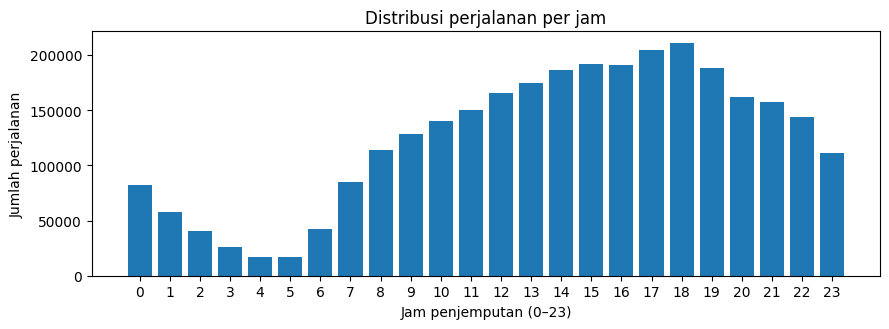

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(agregasi["jam"], agregasi["jumlah_perjalanan"])
ax.set_xlabel("Jam penjemputan (0–23)")
ax.set_ylabel("Jumlah perjalanan")
ax.set_title("Distribusi perjalanan per jam")
ax.set_xticks(range(0, 24))
fig.tight_layout()
fig.savefig(f"{DIR_SIMPAN}/distribusi_per_jam.png", dpi=150)
plt.show()

N · Tabel bahan analisis

In [29]:
kinerja = pd.DataFrame(catatan)
display(kinerja)

d = kinerja.groupby("langkah")["detik"].last()
ringkasan = pd.Series({
    "Dataset sintetis?"            : SINTETIS,
    "Memori semua kolom (MB)"      : round(mem_penuh, 1),
    "Memori kolom terpilih (MB)"   : round(mem_pilih, 1),
    "Rasio memori penuh/terpilih"  : round(mem_penuh / mem_pilih, 2),
    "Rasio waktu baca penuh/pilih" : round(d["baca semua kolom"] / d["baca kolom terpilih"], 2),
    "Rasio jumlah kolom"           : round(meta.num_columns / len(KOLOM), 2),
    "Hemat optimasi tipe (%)"      : round(100 * (1 - sesudah / sebelum), 1),
    "Memori pyarrow backend (MB)"  : round(mem_pa, 1),
    "Ukuran Parquet (MB)"          : round(ukuran_parquet, 1),
    "Ukuran CSV (MB)"              : round(ukuran_csv, 1),
    "Rasio CSV/Parquet"            : round(ukuran_csv / ukuran_parquet, 2),
    "Baris dibuang (%)"            : round(100 * (1 - len(bersih) / len(df)), 2),
})
ringkasan

,langkah,detik,delta_rss_mb
0,unduh dataset,0.35,1.9
1,baca semua kolom,1.80,482.3
2,baca kolom terpilih,1.18,221.5
3,baca kolom terpilih (pyarrow backend),0.78,188.7
4,tulis CSV,42.95,5.7
5,agregasi chunking,3.72,20.7
6,spark count,3.00,0.0
7,spark agregasi,8.28,0.0


,0
Dataset sintetis?,False
Memori semua kolom (MB),565.6
Memori kolom terpilih (MB),187.2
Rasio memori penuh/terpilih,3.02
Rasio waktu baca penuh/pilih,1.53
Rasio jumlah kolom,2.38
Hemat optimasi tipe (%),35.9
Memori pyarrow backend (MB),190.1
Ukuran Parquet (MB),45.5
Ukuran CSV (MB),226.2


O · Studi kasus


In [30]:
bersih["hari"]            = bersih["tpep_pickup_datetime"].dt.day_name()
bersih["akhir_pekan"]     = bersih["tpep_pickup_datetime"].dt.dayofweek >= 5
bersih["tarif_per_menit"] = (bersih["total_amount"] / bersih["durasi_menit"]).round(3)

ringkas = (bersih
    .groupby(["akhir_pekan", "jam"])
    .agg(jumlah=("total_amount", "size"),
         rata_durasi=("durasi_menit", "mean"),
         rata_tarif_per_menit=("tarif_per_menit", "mean"))
    .round(2))
ringkas.head(12)

jumlah  rata_durasi  rata_tarif_per_menit
akhir_pekan jam                                           
False       0     35351        14.10                  2.57
            1     17516        13.04                  2.66
            2      9452        12.23                  2.63
            3      6238        12.87                  2.72
            4      6192        14.79                  2.81
            5     12462        14.63                  2.82
            6     35728        14.57                  2.33
            7     74157        14.66                  2.07
            8     98431        14.82                  1.90
            9    103263        15.03                  1.90
            10   105228        15.24                  1.89
            11   108784        15.25                  1.86

In [31]:
# Dinormalisasi per hari, karena jumlah hari kerja dan akhir pekan dalam sebulan tidak sama
periode = bersih["tpep_pickup_datetime"].dt.to_period("M")
kasus   = bersih[periode == periode.mode()[0]].copy()   # buang baris nyasar di luar bulan utama
kasus["tanggal"] = kasus["tpep_pickup_datetime"].dt.date

n_hari = kasus.groupby("akhir_pekan")["tanggal"].nunique()
pola = (kasus.groupby(["akhir_pekan", "jam"]).size()
        .unstack(0).div(n_hari, axis=1).round(1)
        .rename(columns={False: "Hari kerja", True: "Akhir pekan"}))

semua_hari = (kasus.groupby("jam").size() / kasus["tanggal"].nunique()).round(1)
tpm = kasus.groupby("jam")["tarif_per_menit"].median().round(3)
dur = kasus.groupby("jam")["durasi_menit"].median().round(1)

jam_sibuk = semua_hari.nlargest(3).index.tolist()
print("Jumlah hari:", n_hari.to_dict())
print(f"(1) Permintaan tertinggi jam {semua_hari.idxmax()} ({semua_hari.max():,} perjalanan/hari), "
      f"terendah jam {semua_hari.idxmin()} ({semua_hari.min():,}/hari)")
print(f"(2) Puncak hari kerja jam {pola['Hari kerja'].idxmax()}, "
      f"puncak akhir pekan jam {pola['Akhir pekan'].idxmax()}")
print(f"(3) Jam sibuk {jam_sibuk}: median durasi {dur[jam_sibuk].mean():.1f} mnt, "
      f"median tarif/menit {tpm[jam_sibuk].mean():.3f} vs jam lain "
      f"{dur.drop(jam_sibuk).mean():.1f} mnt, {tpm.drop(jam_sibuk).mean():.3f}")

tabel_kasus = pd.concat([pola, semua_hari.rename("Rata2 per hari"),
                         dur.rename("Median durasi"), tpm.rename("Median tarif/menit")], axis=1)
tabel_kasus.to_csv(f"{DIR_SIMPAN}/studi_kasus_per_jam.csv")
tabel_kasus

Jumlah hari: {False: 22, True: 9}
(1) Permintaan tertinggi jam 18 (6,801.9 perjalanan/hari), terendah jam 4 (536.1/hari)
(2) Puncak hari kerja jam 18, puncak akhir pekan jam 16
(3) Jam sibuk [18, 17, 15]: median durasi 12.2 mnt, median tarif/menit 1.821 vs jam lain 11.2 mnt, 2.001


,Hari kerja,Akhir pekan,Rata2 per hari,Median durasi,Median tarif/menit
jam,,,,,
0,1606.3,5215.3,2654.1,11.4,2.113
1,796.2,4472.2,1863.4,10.7,2.112
2,429.6,3443.7,1304.7,10.4,2.128
3,283.5,2212.0,843.4,10.3,2.200
4,281.5,1158.4,536.1,11.3,2.328
5,566.5,497.6,546.5,10.6,2.544
6,1624.0,730.2,1364.5,9.4,2.165
7,3370.8,1156.9,2728.0,10.4,1.931
8,4474.1,1737.0,3679.5,11.4,1.778


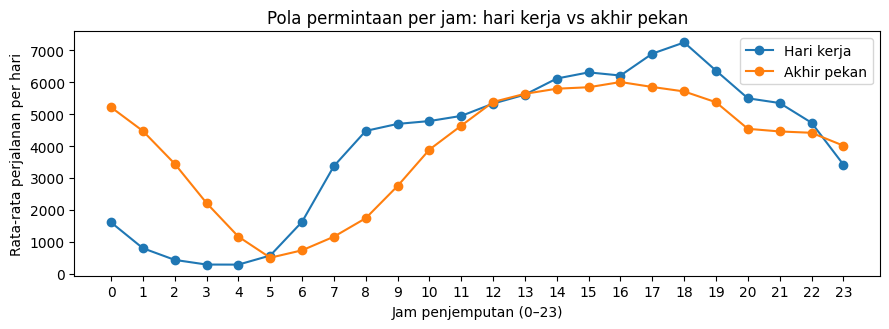

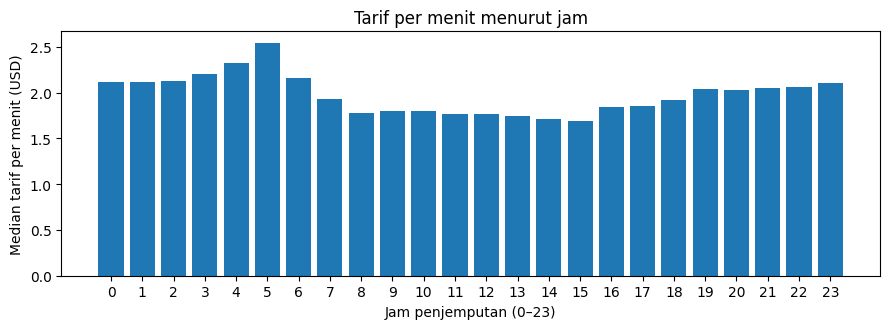

In [32]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(pola.index, pola["Hari kerja"], marker="o", label="Hari kerja")
ax.plot(pola.index, pola["Akhir pekan"], marker="o", label="Akhir pekan")
ax.set_xlabel("Jam penjemputan (0–23)")
ax.set_ylabel("Rata-rata perjalanan per hari")
ax.set_title("Pola permintaan per jam: hari kerja vs akhir pekan")
ax.set_xticks(range(0, 24))
ax.legend()
fig.tight_layout()
fig.savefig(f"{DIR_SIMPAN}/studi_kasus_pola_hari.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(tpm.index, tpm.values)
ax.set_xlabel("Jam penjemputan (0–23)")
ax.set_ylabel("Median tarif per menit (USD)")
ax.set_title("Tarif per menit menurut jam")
ax.set_xticks(range(0, 24))
fig.tight_layout()
fig.savefig(f"{DIR_SIMPAN}/studi_kasus_tarif_per_menit.png", dpi=150)
plt.show()

P · Latihan


In [33]:
# Latihan 1
bersih.nlargest(5, "trip_distance")

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount,durasi_menit,jam,hari,akhir_pekan,tarif_per_menit
1748933,2023-01-19 16:29:36,2023-01-19 18:46:01,1.0,96.70,1,350.000000,50.0,440.750000,136.416667,16,Thursday,False,3.231
526988,2023-01-07 04:29:56,2023-01-07 06:06:16,2.0,93.05,2,542.000000,0.0,564.049988,96.333333,4,Saturday,True,5.855
2402193,2023-01-26 04:55:45,2023-01-26 07:18:50,1.0,92.60,1,262.500000,20.0,312.799988,143.083333,4,Thursday,False,2.186
2902389,2023-01-31 07:04:24,2023-01-31 09:32:54,1.0,92.00,1,334.100006,10.0,368.149994,148.500000,7,Tuesday,False,2.479
927215,2023-01-11 14:23:55,2023-01-11 16:17:58,1.0,90.63,2,250.000000,0.0,272.299988,114.050000,14,Wednesday,False,2.388


In [34]:
# Latihan 2
for n in [100_000, 1_000_000]:
    b, t, _ = ukur(f"agregasi chunking {n:,}", lambda: agregasi_bertahap(CSV, ukuran_chunk=n))
pd.DataFrame(catatan).query("langkah.str.startswith('agregasi chunking')", engine="python")

[agregasi chunking 100,000] 3.84 s | RSS +22.9 MB
[agregasi chunking 1,000,000] 6.06 s | RSS +28.7 MB


,langkah,detik,delta_rss_mb
5,agregasi chunking,3.72,20.7
8,"agregasi chunking 100,000",3.84,22.9
9,"agregasi chunking 1,000,000",6.06,28.7


In [35]:
# Latihan 3
fare = bersih["fare_amount"].astype("float64")
bersih["persen_tip"] = bersih["tip_amount"].astype("float64") / fare.where(fare > 0) * 100  # fare<=0 -> NaN
print("Baris fare_amount <= 0 (diabaikan):", int((fare <= 0).sum()))
bersih.groupby("payment_type", observed=True)["persen_tip"].agg(["count", "mean", "median"]).round(2)

Baris fare_amount <= 0 (diabaikan): 186


,count,mean,median
payment_type,,,
0,64100,20.23,22.49
1,2385053,25.91,26.13
2,512885,0.00,0.00
3,9145,0.02,0.00
4,15542,0.15,0.00


In [36]:
# Latihan 4
hasil_kompresi = []
for komp in ["snappy", "gzip"]:
    p = os.path.join(DIR_KERJA, f"bersih_{komp}.parquet")
    ukur(f"tulis parquet {komp}", lambda: bersih.to_parquet(p, index=False, compression=komp))
    hasil_kompresi.append({"kompresi": komp,
                           "ukuran_mb": round(os.path.getsize(p) / 1024**2, 1),
                           "detik": catatan[-1]["detik"]})
pd.DataFrame(hasil_kompresi)

[tulis parquet snappy] 2.14 s | RSS +46.7 MB
[tulis parquet gzip] 65.02 s | RSS -12.5 MB


,kompresi,ukuran_mb,detik
0,snappy,63.7,2.14
1,gzip,51.3,65.02


In [37]:
# Latihan 5
spark = buat_spark()
bersihkan_spark(spark.read.parquet(PATH)).createOrReplaceTempView("trips")

spark_jam = spark.sql("""
    SELECT HOUR(tpep_pickup_datetime)   AS jam,
           COUNT(*)                     AS jumlah,
           ROUND(AVG(trip_distance), 2) AS rata_jarak,
           ROUND(AVG(total_amount), 2)  AS rata_tarif
    FROM trips
    GROUP BY HOUR(tpep_pickup_datetime)
    ORDER BY jam
""")
df_spark = pd.DataFrame([r.asDict() for r in spark_jam.collect()])
spark.stop()

banding = df_spark.merge(agregasi[["jam", "jumlah_perjalanan"]], on="jam", how="outer")
banding["selisih"] = banding["jumlah"] - banding["jumlah_perjalanan"]
print("Selisih maksimum:", int(banding["selisih"].abs().max()))
banding

Selisih maksimum: 0


,jam,jumlah,rata_jarak,rata_tarif,jumlah_perjalanan,selisih
0,0,82289,4.04,28.86,82289,0
1,1,57766,3.53,26.45,57766,0
2,2,40445,3.28,25.06,40445,0
3,3,26146,3.58,26.26,26146,0
4,4,16618,4.79,31.72,16618,0
5,5,16940,6.03,36.75,16940,0
6,6,42300,4.80,30.63,42300,0
7,7,84569,3.69,26.89,84569,0
8,8,114064,3.08,25.21,114064,0
9,9,127988,3.09,25.51,127988,0


Q · Tugas 1–3


In [40]:
# Tugas 1 & 2: bulan lain + perbandingan
def proses_bulan(bulan, seed=7):
    url  = f"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{bulan}.parquet"
    path = os.path.join(DIR_KERJA, f"yellow_tripdata_{bulan}.parquet")
    if not os.path.exists(path):
        try:
            ukur(f"unduh {bulan}", lambda: unduh(url, path))
        except Exception as e:
            print("Unduhan gagal:", e)
            if os.path.exists(path):
                os.remove(path)
    if not (os.path.exists(path) and parquet_valid(path)):
        print("Memakai data SINTETIS untuk", bulan)
        bangkitkan_sintetis(seed=seed).to_parquet(path, index=False,
                                                  coerce_timestamps="us", allow_truncated_timestamps=True)
    m = pq.ParquetFile(path)
    print(f"{bulan}: {m.metadata.num_rows:,} baris | kolom: {m.schema.names}")

    d = ukur(f"baca {bulan}", lambda: pd.read_parquet(path, columns=KOLOM))
    d["durasi_menit"] = (d["tpep_dropoff_datetime"] - d["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = ((d["trip_distance"] > 0) & (d["trip_distance"] < 100) &
          d["durasi_menit"].between(1, 180) & (d["total_amount"] > 0))
    d = d.loc[ok].copy()
    d["jam"] = d["tpep_pickup_datetime"].dt.hour
    return (d.groupby("jam")
             .agg(jumlah_perjalanan=("total_amount", "size"),
                  rata_jarak=("trip_distance", "mean"),
                  rata_durasi=("durasi_menit", "mean"),
                  rata_tarif=("total_amount", "mean"),
                  median_tarif=("total_amount", "median"))
             .round(2).reset_index())

BULAN_LAIN = "2023-07"
agregasi_lain = proses_bulan(BULAN_LAIN)
agregasi_lain.to_csv(f"{DIR_SIMPAN}/agregasi_per_jam_{BULAN_LAIN}.csv", index=False)

perbandingan = pd.DataFrame({
    "jam": agregasi["jam"],
    "jumlah_2023-01": agregasi["jumlah_perjalanan"],
    f"jumlah_{BULAN_LAIN}": agregasi_lain["jumlah_perjalanan"],
})
perbandingan["porsi_2023-01_%"] = (100 * perbandingan["jumlah_2023-01"] / perbandingan["jumlah_2023-01"].sum()).round(2)
perbandingan[f"porsi_{BULAN_LAIN}_%"] = (100 * perbandingan[f"jumlah_{BULAN_LAIN}"] / perbandingan[f"jumlah_{BULAN_LAIN}"].sum()).round(2)
perbandingan.to_csv(f"{DIR_SIMPAN}/perbandingan_dua_bulan.csv", index=False)
perbandingan

2023-07: 2,907,108 baris | kolom: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']
[baca 2023-07] 0.80 s | RSS +161.5 MB


,jam,jumlah_2023-01,jumlah_2023-07,porsi_2023-01_%,porsi_2023-07_%
0,0,82289,85987,2.75,3.05
1,1,57766,59980,1.93,2.13
2,2,40445,40812,1.35,1.45
3,3,26146,26000,0.88,0.92
4,4,16618,16637,0.56,0.59
5,5,16940,16913,0.57,0.60
6,6,42300,38422,1.42,1.36
7,7,84569,69358,2.83,2.46
8,8,114064,103647,3.82,3.68
9,9,127988,118788,4.28,4.22


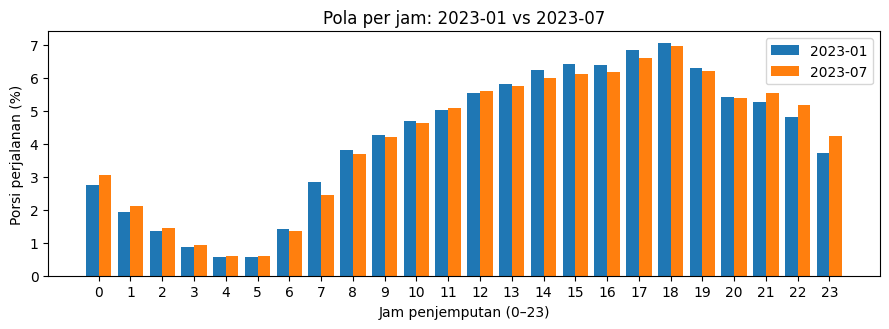

In [41]:
fig, ax = plt.subplots(figsize=(9, 3.4))
lebar = 0.4
ax.bar(perbandingan["jam"] - lebar/2, perbandingan["porsi_2023-01_%"], width=lebar, label="2023-01")
ax.bar(perbandingan["jam"] + lebar/2, perbandingan[f"porsi_{BULAN_LAIN}_%"], width=lebar, label=BULAN_LAIN)
ax.set_xlabel("Jam penjemputan (0–23)")
ax.set_ylabel("Porsi perjalanan (%)")
ax.set_title(f"Pola per jam: 2023-01 vs {BULAN_LAIN}")
ax.set_xticks(range(0, 24))
ax.legend()
fig.tight_layout()
fig.savefig(f"{DIR_SIMPAN}/perbandingan_dua_bulan.png", dpi=150)
plt.show()

In [39]:
# Tugas 3 + simpan ulang semua pengukuran (sel terakhir)
kinerja = pd.DataFrame(catatan)
kinerja.to_csv(f"{DIR_SIMPAN}/pengukuran_kinerja.csv", index=False)
print("Langkah paling mahal:\n", kinerja.sort_values("detik", ascending=False).head(5))
print("\nIsi folder Drive:", sorted(os.listdir(DIR_SIMPAN)))

Langkah paling mahal:
                         langkah  detik  delta_rss_mb
11           tulis parquet gzip  65.02         -12.5
4                     tulis CSV  42.95           5.7
7                spark agregasi   8.28           0.0
9   agregasi chunking 1,000,000   6.06          28.7
8     agregasi chunking 100,000   3.84          22.9

Isi folder Drive: ['agregasi_per_jam.csv', 'agregasi_per_jam.parquet', 'agregasi_per_jam_2023-07.csv', 'distribusi_per_jam.png', 'pengukuran_kinerja.csv', 'perbandingan_dua_bulan.csv', 'studi_kasus_per_jam.csv', 'studi_kasus_pola_hari.png', 'studi_kasus_tarif_per_menit.png']
